# Policy counterfactual: position limits

Figure 3E's design (100 bettors with budget 100 and expertise 0.9, a whale with ρ = 0.5 and
valuation 0.7 entering at period 0, everyone at log utility, T = 100, 500 runs per condition,
Figure 3E's seeds), with one change: every trader, whale included, may hold at most a fixed
net position (YES or NO) in contracts. Orders that would take a trader past its limit are cut
to fit.

The limits mirror three real regimes:

- **CFTC**: outside the delivery month, futures limits are 10% of open interest (for the first
  50,000 contracts). Here: 10% of the mean open interest of the no-limit runs.
- **Kalshi**: $25,000 per market for retail traders.
- **PredictIt**: $3,500 per contract since 2025; $850 before.

Three looser, hypothetical limits (5%, 10% and 25% of the market) fill the range between these
and no limit; the whale's unlimited position is about 17% of the market.

The model is scale-free, so a dollar limit only means something relative to the size of the
market. Dollar limits are converted with `MARKET_SIZE`, the total money in the market (the whale's
and everyone else's), and a position is measured by its payout ($1 per contract).

- **A** Mean price error (midquote − outcome) with 95% bands, and the expected shift ρΔ without
  a limit.
- **B** The whale's mean net YES position. Colour identifies the position limit.
- **C** Capital locked in open contracts, split between ordinary bettors (dashed) and the whale
  (dotted). Colour identifies the position limit. YES holders lock p per contract and NO holders
  1 − p, as in the Dash app.

Two versions: the outcome following Figure 3E's random walk, and the outcome fixed at η = 0.5
(Figure 4D–E's convention; the whale then never faces a price above its valuation, and ρΔ is the
theory's exact steady state). Simulations are cached in `sim_output/` (about 5 minutes each on 4
processes); limits already in a file are kept, so an interrupted run resumes. Set `RERUN = True`
to redo them. Saves separate A and BC figures: `policy_counterfactual_A`, `policy_counterfactual_BC`,
`policy_counterfactual_fixed_eta_A` and `policy_counterfactual_fixed_eta_BC` (PDF and PNG)
in this folder.

In [13]:
import sys
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import get_context
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter, LogLocator, FuncFormatter, NullFormatter

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO))
import figure_style as style
import paper_figures as pf
from bettor import Bettor, whale_budget

style.apply()
RERUN = False


In [14]:
# Colour of each limit's lines: any name in figure_style.PALETTE (lavender, navy, green, orange,
# ruby, violet, indigo, teal, steel, amber, crimson, lilac, sky, tangerine, royal, aqua, slate,
# plum, gold, deep_plum, burnt).
LIMIT_COLORS = {
    "No limit": "indigo",
    "25% of market": "navy",
    "10% of market": "violet",
    "5% of market": "lilac",
    "CFTC (10% of open interest)": "steel",
    "Kalshi retail ($25,000)": "green",
    "PredictIt ($3,500)": "orange",
    "PredictIt before 2025 ($850)": "ruby",
}


In [15]:
MARKET_SIZE = 1_000_000                    # $ in the market, to convert the dollar limits
CFTC_SHARE_OF_OPEN_INTEREST = 0.10
# Cache key -> position limit: a dollar amount, "cftc" (set from the no-limit runs), or None.
# Loosest first; the keys name each limit in the cached CSVs.
LIMITS = {
    "No limit": None,
    "25% of market": 0.25 * MARKET_SIZE,
    "10% of market": 0.10 * MARKET_SIZE,
    "5% of market": 0.05 * MARKET_SIZE,
    "CFTC (10% of open interest)": "cftc",
    "Kalshi retail ($25,000)": 25_000,
    "PredictIt ($3,500)": 3_500,
    "PredictIt before 2025 ($850)": 850,
}
# Legend names; each limit's share of the market is added from the runs (legend_label).
LEGEND_LABELS = {
    "No limit": "No limit",
    "25% of market": "Hypothetical ($250k",
    "10% of market": "Hypothetical ($100k",
    "5% of market": "Hypothetical ($50k",
    "CFTC (10% of open interest)": "CFTC (10% of open interest",
    "Kalshi retail ($25,000)": "Kalshi retail ($25k",
    "PredictIt ($3,500)": "PredictIt ($3.5k",
    "PredictIt before 2025 ($850)": "PredictIt before 2025 ($850",
}

WHALE_SHARE = pf.VALUATION_WHALE_SHARE     # ρ = 0.5
WHALE_VALUATION = 0.7                      # Δ = 0.2, so ρΔ = 0.1
RUNS = pf.VALUATION_RUNS
SEED = pf.VALUATION_SEED                   # Figure 3E's seeds
FIXED_ETA = pf.WHALE_HERDING_ETA           # Figure 4D-E's fixed true outcome (0.5)
SERIES = ("error", "whale_position", "locked_ordinary", "locked_whale")
CSV = pf.SIM_DIR / "policy_counterfactual.csv"
CSV_FIXED_ETA = pf.SIM_DIR / "policy_counterfactual_fixed_eta.csv"


In [16]:
class PositionLimited(Bettor):
    """A bettor whose net position may not exceed position_limit contracts either way
    (None: only the usual limit of its cash)."""
    position_limit = None

    def trade(self, price):
        """Utility-maximising trade at price, over whole contracts that keep the position
        within the limit."""
        if self.position_limit is None:
            return super().trade(price)
        quantities = np.arange(
            max(-(int(self.budget) + self.n_contracts), -self.position_limit - self.n_contracts),
            min(int(self.budget), self.position_limit - self.n_contracts) + 1)
        return quantities[np.argmax(self.exp_utility(price, quantities))]


def capital_locked(record, money):
    """(ordinary bettors', whale's) capital locked in open contracts each period, as shares of
    money. Each contract locks $1 in all: p from its YES holder and 1 - p from its NO holder."""
    open_interest = np.asarray(record["vol_history"][1:], dtype=float) / 2
    price = np.asarray(record["price_history"][1:], dtype=float)
    whale = np.asarray(record["whale_contracts"], dtype=float)
    whale_locked = np.maximum(whale, 0) * price + np.maximum(-whale, 0) * (1 - price)
    return (open_interest - whale_locked) / money, whale_locked / money


def limit_run(seed, share, fixed_eta=False):
    """One run with every trader's position limited to share × all money in contracts (None:
    no limit), the outcome a random walk or (fixed_eta) held at FIXED_ETA. Returns the SERIES
    as rows."""
    path = np.full(pf.T_MAX + 1, FIXED_ETA) if fixed_eta else pf.make_election_path(seed)
    np.random.seed(seed)
    population = [PositionLimited(budget=pf.DESIGN_BUDGET, expertise=pf.DESIGN_EXPERTISE,
                                  risk_av=1.0) for _ in range(pf.N_BETTORS)]
    population.append(PositionLimited(budget=whale_budget(population, WHALE_SHARE),
                                      market_valuation=WHALE_VALUATION, risk_av=1.0, whale=True))
    money = sum(b.budget for b in population)
    for bettor in population:
        bettor.position_limit = None if share is None else int(share * money)
    record = pf.standard_market(seed, population, path)
    prices = pd.Series(record["midquote"]).ffill().fillna(pf.INITIAL_PRICE).to_numpy()
    position = np.asarray(record["whale_contracts"], dtype=float)
    return np.vstack([prices - path[:pf.T_MAX], position, *capital_locked(record, money)])


def values(paths, name, series):
    """(runs × periods) array of one series for one limit."""
    rows = paths[(paths["limit"] == name) & (paths["series"] == series)]
    return rows.filter(regex=r"^t\d+$").to_numpy()


def limit_share(limit, paths):
    """A limit as a share of all money: dollars over MARKET_SIZE, or for "cftc" 10% of the
    no-limit runs' mean open interest (all locked capital, as each contract locks $1)."""
    if limit is None:
        return None
    if limit == "cftc":
        open_interest = sum(values(paths, "No limit", s) for s in ("locked_ordinary", "locked_whale"))
        return CFTC_SHARE_OF_OPEN_INTEREST * open_interest.mean()
    return limit / MARKET_SIZE


def load_paths(csv, fixed_eta=False, rerun=RERUN):
    """Every run's SERIES for every limit, one row per (limit, run, series), with the limit's
    share of all money; simulates the limits missing from csv (no limit first, as the CFTC
    limit depends on it) and saves after each."""
    paths = pd.read_csv(csv) if csv.exists() and not rerun else pd.DataFrame(columns=["limit"])
    for name, limit in LIMITS.items():
        if name in set(paths["limit"]):
            continue
        share = limit_share(limit, paths)
        print(f"{name}: {RUNS} runs on {pf.N_WORKERS} processes")
        with ProcessPoolExecutor(pf.N_WORKERS, mp_context=get_context("fork")) as pool:
            runs = list(pool.map(limit_run, SEED + np.arange(RUNS), [share] * RUNS,
                                 [fixed_eta] * RUNS, chunksize=8))
        frame = pd.DataFrame(np.vstack(runs), columns=[f"t{t}" for t in range(pf.T_MAX)])
        frame.insert(0, "limit", name)
        frame.insert(1, "share_of_money", share)
        frame.insert(2, "run", np.repeat(np.arange(RUNS), len(SERIES)))
        frame.insert(3, "series", np.tile(SERIES, RUNS))
        paths = pd.concat([paths, frame], ignore_index=True)
        paths.to_csv(csv, index=False)
    return paths


In [17]:
def legend_label(paths, name):
    """A limit's legend name with its share of the market, e.g. "Kalshi retail ($25k, 2.5%)"."""
    share = paths.loc[paths["limit"] == name, "share_of_money"].iloc[0]
    if pd.isna(share):
        return LEGEND_LABELS[name]
    return f"{LEGEND_LABELS[name]}, {100 * share:.2g}%)"


def plot_mean(ax, runs, color, **line):
    """Mean over runs, with a 95% confidence band."""
    n = np.sum(np.isfinite(runs), axis=0)
    mean = np.nanmean(runs, axis=0)
    half_width = 1.96 * np.nanstd(runs, axis=0, ddof=1) / np.sqrt(n)
    ax.plot(mean, color=color, linewidth=1.2, **line)
    ax.fill_between(np.arange(len(mean)), mean - half_width, mean + half_width,
                    color=color, alpha=0.16, linewidth=0)


def summary(paths):
    """Per-limit means: the limit, error early and late, the whale's final position, peak
    ordinary capital locked."""
    rows = []
    for name in LIMITS:
        error = values(paths, name, "error")
        rows.append({"limit": name,
                     "share_of_money": paths.loc[paths["limit"] == name, "share_of_money"].iloc[0],
                     "error_t0_9": error[:, :10].mean(), "error_t50_99": error[:, 50:].mean(),
                     "whale_position_t99": values(paths, name, "whale_position")[:, -1].mean(),
                     "peak_ordinary_locked": values(paths, name, "locked_ordinary").max(axis=1).mean()})
    return pd.DataFrame(rows).round(4)


def plot_policy(paths, name):
    """Save two figures: A mean price error; BC whale position and capital locked."""
    # Figure 1: Panel A alone, using the full two-column page width.
    fig_a, ax_error = plt.subplots(
        1, 1, figsize=(style.PAGE_WIDTH, 4), layout="constrained")
    fig_a.get_layout_engine().set(rect=(0, 0, 1, 0.86))

    for limit in LIMITS:
        color = style.color(LIMIT_COLORS[limit])
        plot_mean(ax_error, values(paths, limit, "error"), color,
                  label=legend_label(paths, limit))

    ax_error.axhline(0, color="#BBBBBB", linewidth=0.8)
    ax_error.axhline(WHALE_SHARE * (WHALE_VALUATION - pf.INITIAL_PRICE),
                     color="black", linestyle=":", linewidth=1,
                     label=r"Theoretical with no limit ($\rho\Delta$)")
    ax_error.set(ylabel="Price − Outcome", 
                 xlim=(0, pf.T_MAX), xlabel="Time Since Whale Entry")
    pf.style_axis(ax_error)

    handles_a, labels_a = ax_error.get_legend_handles_labels()
    # Put the theoretical benchmark first, followed by the position-limit regimes.
    theory_idx = labels_a.index(r"Theoretical with no limit ($\rho\Delta$)")
    handles_a = [handles_a[theory_idx]] + handles_a[:theory_idx] + handles_a[theory_idx+1:]
    labels_a = [labels_a[theory_idx]] + labels_a[:theory_idx] + labels_a[theory_idx+1:]
    fig_a.legend(handles_a, labels_a, loc="outside lower center", ncols=3,
                 title="Position limit")
    style.label_panels(((ax_error, "A"),), lift=8)
    style.save(fig_a, Path(f"{name}_A"), f"{name}_A")

    # Figure 2: Panels B and C remain separate, side-by-side axes.
    # B shows the whale's net YES position. C shows capital locked by
    # ordinary bettors and the whale, on a logarithmic percentage scale.
    fig_bc, (ax_position, ax_locked) = plt.subplots(
        1, 2, figsize=(style.PAGE_WIDTH, 3.9), layout="constrained")
    fig_bc.get_layout_engine().set(rect=(0, 0, 1, 0.82))

    for limit in LIMITS:
        color = style.color(LIMIT_COLORS[limit])
        plot_mean(ax_position, values(paths, limit, "whale_position") / 1000,
                  color, linestyle="-")
        plot_mean(ax_locked, values(paths, limit, "locked_ordinary"),
                  color, linestyle="--")
        plot_mean(ax_locked, values(paths, limit, "locked_whale"),
                  color, linestyle=":")

    ax_position.set(ylabel="Net YES position (thousands)",
                    xlim=(0, pf.T_MAX), xlabel="Time Since Whale Entry")
    pf.style_axis(ax_position)

    ax_locked.set(ylabel="Capital locked (% of all money)",
                #   title="Capital Locked",
                  xlim=(0, pf.T_MAX), xlabel="Time Since Whale Entry")
    ax_locked.set_yscale("log")
    # Label only decades; hide minor labels to avoid crowded powers of ten.
    ax_locked.yaxis.set_major_locator(
        LogLocator(base=10.0, subs=(1.0,), numticks=3))
    ax_locked.yaxis.set_major_formatter(
        FuncFormatter(lambda y, _: f"{100*y:g}%"))
    ax_locked.yaxis.set_minor_locator(
        LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1))
    ax_locked.yaxis.set_minor_formatter(NullFormatter())
    ax_locked.tick_params(axis="y", which="minor", length=0)
    pf.style_axis(ax_locked)

    # Shared key: colours identify position limits; line styles identify series.
    limit_handles = [
        Line2D([], [], color=style.color(LIMIT_COLORS[limit]), linewidth=1.5,
               label=legend_label(paths, limit))
        for limit in LIMITS
    ]
    measure_handles = [
        Line2D([], [], color="black", linewidth=1.2, linestyle="-",
               label="Whale net YES position (Panel B)"),
        Line2D([], [], color="black", linewidth=1.2, linestyle="--",
               label="Ordinary capital locked (Panel C)"),
        Line2D([], [], color="black", linewidth=1.2, linestyle=":",
               label="Whale capital locked (Panel C)"),
    ]
    fig_bc.legend(limit_handles + measure_handles, 
                  [h.get_label() for h in limit_handles + measure_handles],
                  loc="outside lower center", ncols=3,
                  title="Colour = position limit; line style = measure")
    style.label_panels(((ax_position, "B"), (ax_locked, "C")), lift=8)
    style.save(fig_bc, Path(f"{name}_BC"), f"{name}_BC")


## Outcome following a random walk (Figure 3E's paths)

,limit,share_of_money,error_t0_9,error_t50_99,whale_position_t99,peak_ordinary_locked
0,No limit,NaN,0.0953,0.0877,3416.982,0.5293
1,25% of market,0.2500,0.0900,0.0406,1536.486,0.3629
2,10% of market,0.1000,0.0487,0.0177,656.016,0.2963
3,5% of market,0.0500,0.0218,0.0095,335.172,0.2756
4,CFTC (10% of open interest),0.0317,0.0121,0.0061,215.564,0.2683
5,"Kalshi retail ($25,000)",0.0250,0.0094,0.0050,165.608,0.2645
6,"PredictIt ($3,500)",0.0035,0.0009,0.0005,25.244,0.1301
7,PredictIt before 2025 ($850),0.0008,-0.0003,0.0001,5.864,0.0388


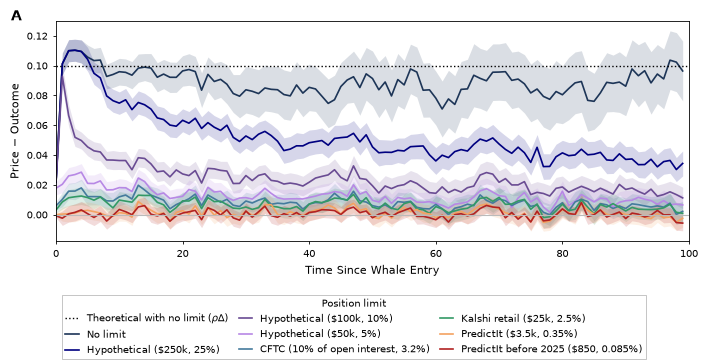

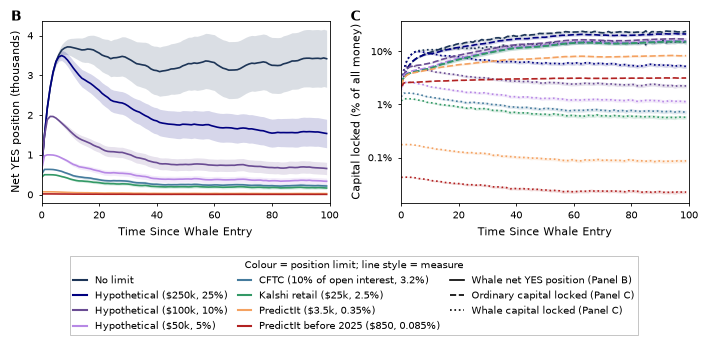

In [18]:
paths = load_paths(CSV)
display(summary(paths))
plot_policy(paths, "policy_counterfactual")


## Outcome fixed at η = 0.5

,limit,share_of_money,error_t0_9,error_t50_99,whale_position_t99,peak_ordinary_locked
0,No limit,NaN,0.0960,0.1036,4059.416,0.1003
1,25% of market,0.2500,0.0960,0.1036,4059.416,0.1003
2,10% of market,0.1000,0.0546,0.0513,1999.906,0.0674
3,5% of market,0.0500,0.0244,0.0264,1000.000,0.0526
4,CFTC (10% of open interest),0.0198,0.0093,0.0105,396.000,0.0478
5,"Kalshi retail ($25,000)",0.0250,0.0119,0.0131,500.000,0.0482
6,"PredictIt ($3,500)",0.0035,0.0014,0.0021,70.000,0.0467
7,PredictIt before 2025 ($850),0.0008,0.0006,0.0012,17.000,0.0294


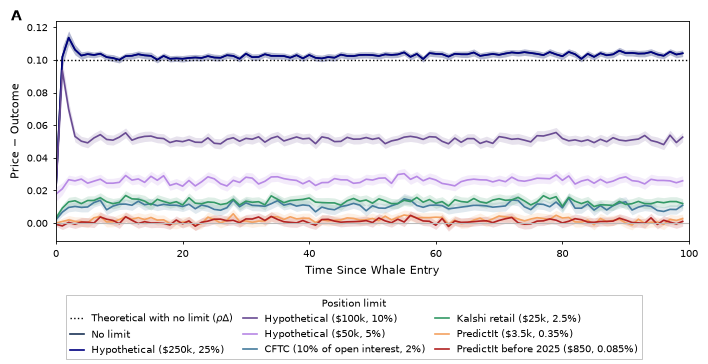

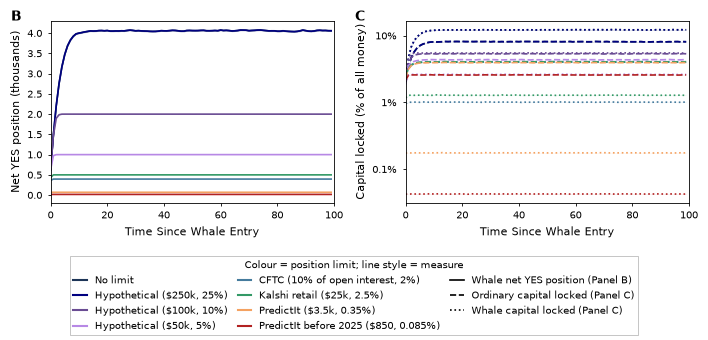

In [19]:
paths_fixed_eta = load_paths(CSV_FIXED_ETA, fixed_eta=True)
display(summary(paths_fixed_eta))
plot_policy(paths_fixed_eta, "policy_counterfactual_fixed_eta")
